In [24]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist

print("TensorFlow version:", tf.__version__)
print("Environment ready!")

TensorFlow version: 2.21.0
Environment ready!


In [25]:
#Load MNIST dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


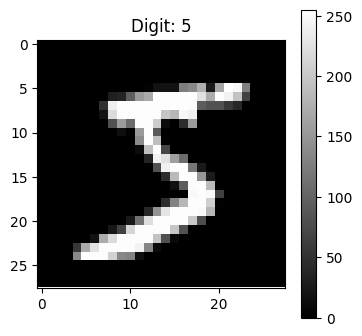

In [26]:
#first digit visualization
plt.figure(figsize=(4,4))

plt.imshow(X_train[0], cmap='gray')

plt.title(f"Digit: {y_train[0]}")
plt.colorbar()
plt.show()

In [27]:
# Display one image as a numerical matrix
#inspect an actual MNIST image using Python

print("Image shape:", X_train[0].shape)

print("Pixel values:")
print(X_train[0])

Image shape: (28, 28)
Pixel values:
[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   3  18  18  18 126 136
  175  26 166 255 247 127   0   0   0   0]
 [  0   0   0   0   0   0   0   0  30  36  94 154 170 253 253 253 253 253
  225 172 253 242 195  64   0   0   0   0]
 [  0   0   0   0   0   0   0  49 238 253 253 253 253 253 253 253 253 251
   93  82  82  56  39   0   0   0   0   0]
 [  0   0   0   0   0   0   

In [28]:
print("First pixel:", X_train[0][0][0])

print("Second pixel:", X_train[0][0][1])

print("Pixel at row 14, column 14:",
      X_train[0][14][14])

First pixel: 0
Second pixel: 0
Pixel at row 14, column 14: 240


In [29]:
image = X_train[0]

flattened_image = image.reshape(784)

print("Original shape:", image.shape)
print("Flattened shape:", flattened_image.shape)

Original shape: (28, 28)
Flattened shape: (784,)


In [30]:
# Convert pixel values to float32
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

# Normalize pixel values
X_train = X_train / 255.0
X_test = X_test / 255.0

# Check normalized values
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Minimum: 0.0
Maximum: 1.0
Training shape: (60000, 28, 28)
Testing shape: (10000, 28, 28)


In [31]:
X_train = np.expand_dims(X_train, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [32]:
print("Single image before:",
      X_train[0].shape)

print("Single image after:",
      X_train[0].shape)

Single image before: (28, 28, 1)
Single image after: (28, 28, 1)


In [33]:
#Build the CNN model
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),

    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(64, activation='relu'),

    tf.keras.layers.Dense(10, activation='softmax')
])

In [34]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 5408)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       346,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 347,146 (1.32 MB)

 Trainable params: 347,146 (1.32 MB)

 Non-trainable params: 0 (0.00 B)

In [35]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [36]:
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=100,
    validation_split=0.1
)

Epoch 1/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 39s 68ms/step - accuracy: 0.9265 - loss: 0.2558 - val_accuracy: 0.9777 - val_loss: 0.0805
Epoch 2/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 28s 45ms/step - accuracy: 0.9769 - loss: 0.0767 - val_accuracy: 0.9827 - val_loss: 0.0607
Epoch 3/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 26s 48ms/step - accuracy: 0.9847 - loss: 0.0515 - val_accuracy: 0.9833 - val_loss: 0.0608
Epoch 4/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 26s 47ms/step - accuracy: 0.9883 - loss: 0.0395 - val_accuracy: 0.9867 - val_loss: 0.0521
Epoch 5/5
540/540 ━━━━━━━━━━━━━━━━━━━━ 26s 47ms/step - accuracy: 0.9904 - loss: 0.0323 - val_accuracy: 0.9885 - val_loss: 0.0480


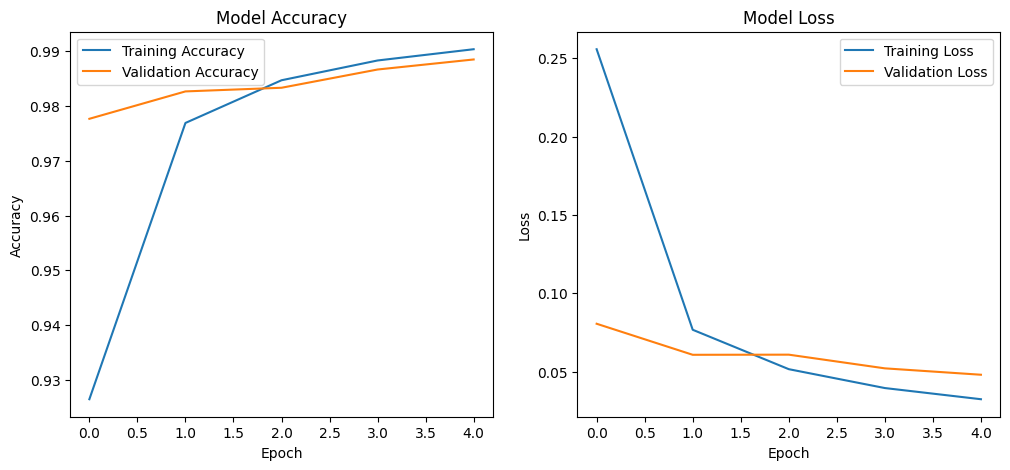

In [37]:
#Let's visualize the learning curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [38]:
#Test on unseen data
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9861 - loss: 0.0402
Test Accuracy: 0.9861000180244446
Test Loss: 0.040159959346055984


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


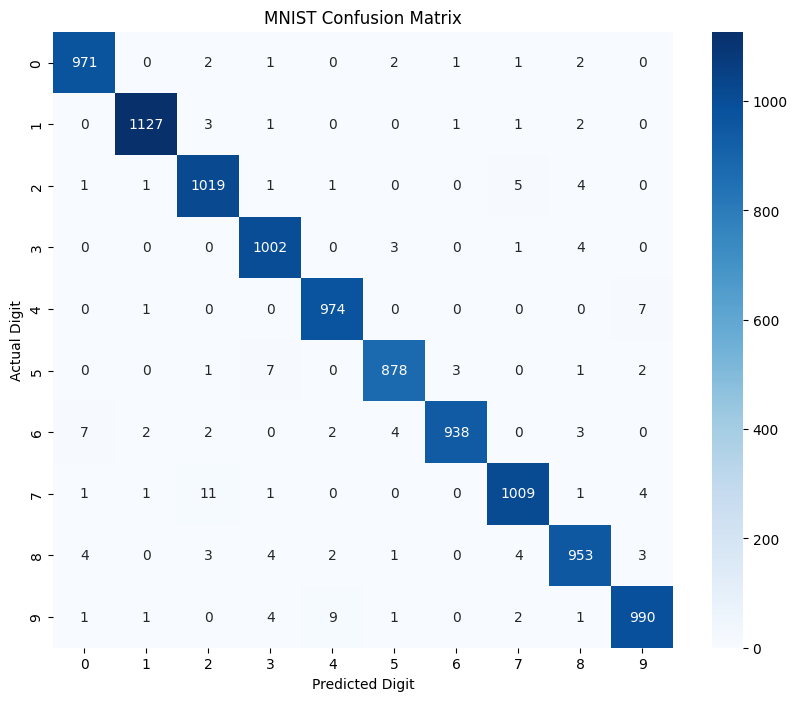

In [39]:
#Confusion matrix
from sklearn.metrics import confusion_matrix
import seaborn as sns

y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.title('MNIST Confusion Matrix')
plt.show()

In [40]:
y_pred_prob = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step


In [41]:
#Convert probabilities into predicted digits
y_pred = np.argmax(y_pred_prob, axis=1)

In [42]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

In [43]:
#Generate the classification report
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9858    0.9908    0.9883       980
           1     0.9947    0.9930    0.9938      1135
           2     0.9789    0.9874    0.9831      1032
           3     0.9814    0.9921    0.9867      1010
           4     0.9858    0.9919    0.9888       982
           5     0.9876    0.9843    0.9860       892
           6     0.9947    0.9791    0.9868       958
           7     0.9863    0.9815    0.9839      1028
           8     0.9815    0.9784    0.9799       974
           9     0.9841    0.9812    0.9826      1009

    accuracy                         0.9861     10000
   macro avg     0.9861    0.9860    0.9860     10000
weighted avg     0.9861    0.9861    0.9861     10000



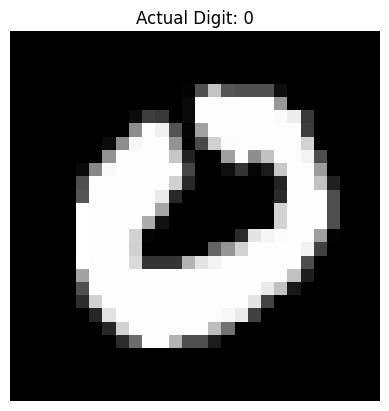

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
Actual Digit: 0
Predicted Digit: 0
Confidence: 99.969246 %


In [44]:
#Predict a handwritten digit!
index = 25

plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
plt.title(f"Actual Digit: {y_test[index]}")
plt.axis('off')
plt.show()

prediction = model.predict(X_test[index:index+1])

predicted_digit = np.argmax(prediction)

print("Actual Digit:", y_test[index])
print("Predicted Digit:", predicted_digit)
print("Confidence:", np.max(prediction) * 100, "%")

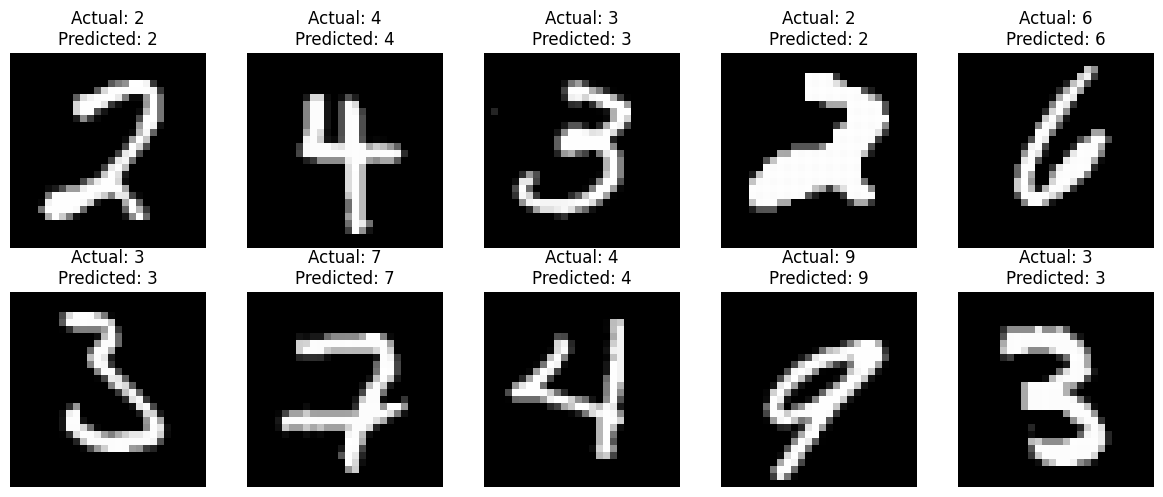

In [45]:
# Next experiment: Test a difficult prediction
import random

indices = random.sample(range(len(X_test)), 10)

plt.figure(figsize=(12, 5))

for i, index in enumerate(indices):
    prediction = model.predict(
        X_test[index:index+1],
        verbose=0
    )

    predicted_digit = np.argmax(prediction)

    plt.subplot(2, 5, i+1)
    plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
    plt.title(
        f"Actual: {y_test[index]}\nPredicted: {predicted_digit}"
    )
    plt.axis('off')

plt.tight_layout()
plt.show()

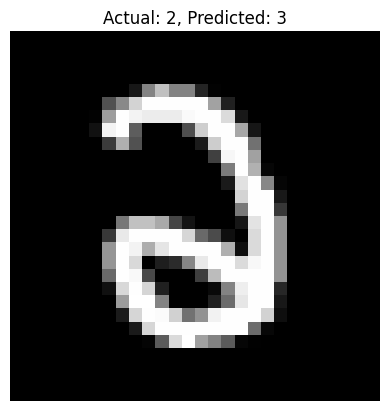

Actual: 2
Predicted: 3
Confidence: 49.857983 %


In [46]:
wrong_indices = np.where(y_pred != y_test)[0]

index = wrong_indices[0]

plt.imshow(X_test[index].reshape(28, 28), cmap='gray')
plt.title(
    f"Actual: {y_test[index]}, Predicted: {y_pred[index]}"
)
plt.axis('off')
plt.show()

print("Actual:", y_test[index])
print("Predicted:", y_pred[index])
print("Confidence:", np.max(y_pred_prob[index]) * 100, "%")

In [47]:
#Let's investigate the model's thinking
probs = y_pred_prob[index]

top3 = np.argsort(probs)[-3:][::-1]

for digit in top3:
    print(f"Digit {digit}: {probs[digit]*100:.2f}%")

Digit 3: 49.86%
Digit 2: 49.36%
Digit 8: 0.69%
